In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [61]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [63]:
df = pd.read_csv('mnist_test.csv')
df

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9996,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9997,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9998,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [64]:
df.isnull().sum()

label    0
1x1      0
1x2      0
1x3      0
1x4      0
        ..
28x24    0
28x25    0
28x26    0
28x27    0
28x28    0
Length: 785, dtype: int64

In [65]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='object', length=785)

In [66]:
x = df.drop(['label'], axis=1)
y = df['label']

In [67]:
x = x / 255.0

In [75]:
x = x.to_numpy()
x = x.reshape(-1, 28, 28)

In [76]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [77]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [78]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

D:\Anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [79]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [80]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_6 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
history = model.fit(
    x_train, y_train,
    epochs=10, batch_size=128,
    validation_split=0.1
)

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7553 - loss: 0.9186 - val_accuracy: 0.8838 - val_loss: 0.4278
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9018 - loss: 0.3529 - val_accuracy: 0.9100 - val_loss: 0.3191
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9229 - loss: 0.2773 - val_accuracy: 0.9275 - val_loss: 0.2744
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9339 - loss: 0.2370 - val_accuracy: 0.9350 - val_loss: 0.2529
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9417 - loss: 0.2074 - val_accuracy: 0.9362 - val_loss: 0.2366
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9476 - loss: 0.1829 - val_accuracy: 0.9475 - val_loss: 0.2205
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9554 - loss: 0.1604 - val_accuracy: 0.9438 - val_loss: 0.2146
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9606 - loss: 0.1436 - val_accuracy: 0.9463 - val_loss

In [82]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9395 - loss: 0.2159
Test Loss: 0.21587124466896057
Test Accuracy: 93.94999742507935 %


In [87]:
pred = model.predict(x_test)

pred_digit = np.argmax(pred[0])
act_digit = np.argmax(y_test[0])

print("Actual Digit :", act_digit)
print("Predicted Digit :", pred_digit)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Actual Digit : 6
Predicted Digit : 6


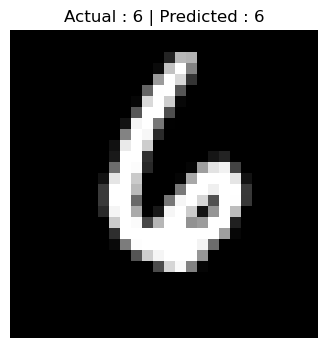

In [86]:
plt.figure(figsize=(6,4))
plt.imshow(x_test[0], cmap='gray')
plt.title(f"Actual : {act_digit} | Predicted : {pred_digit}")
plt.axis("off")
plt.show()

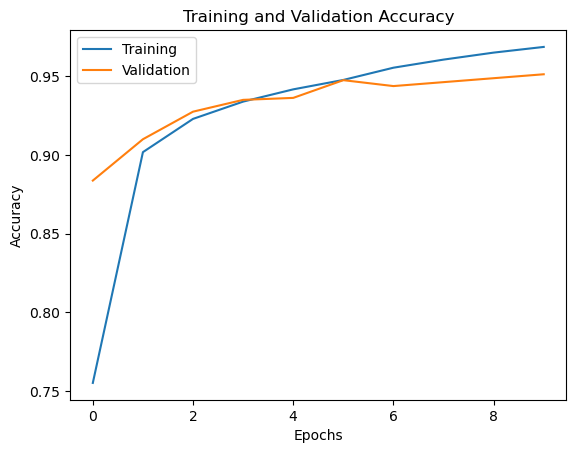

In [88]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend(['Training', 'Validation'])
plt.show()

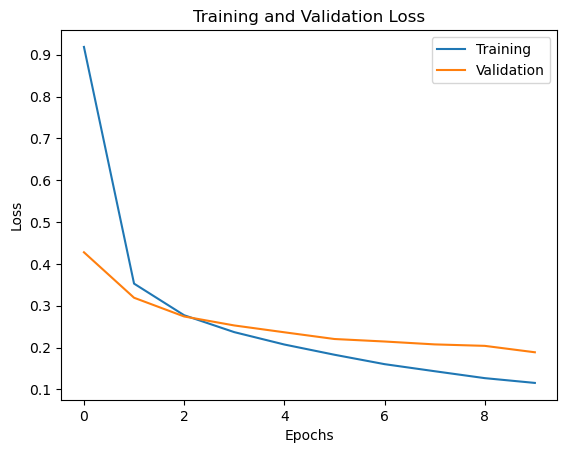

In [89]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend(['Training', 'Validation'])
plt.show()